## Análisis: Recuento

Recuento del proceso: preguntas, datos, técnicas, parámetros elegidos y desempeño de cada técnica

### Utilidades

In [1]:
NOTEBOOK = "a_recuento"
%run ../funciones.ipynb
%run funciones.ipynb

In [2]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


---
### **1. Problema y preguntas**

| Pregunta | Qué busca | Técnicas |
|---|---|---|
| **PQ1: Concentración y cautividad** | Entidades que dependen de pocos proveedores y proveedores que concentran el gasto | Clustering, PageRank y HITS, Recomendación |
| **PQ2: Mercados y competencia** | Mercados que emergen de la co-participación: ¿regionales o por rubro? ¿grupos que siempre compiten? | Comunidades, Embeddings, Clustering |
| **PQ3: Sustitutos y afinidades** | Alternativas para una entidad y relaciones entidad–proveedor atípicas | Recomendación, Predicción de enlaces |

---
### **2. Datos**

In [3]:
staging = tabla("00_EDA", "a_entendimiento", "conteos_staging").query("tabla != 'partes'")   # partes: solo para resolver identidades
bip = tabla("00_EDA", "b_exploracion", "resumen_bipartito").iloc[0]
art = tabla("01_Trans", "c_uso", "resumen_artefactos").set_index("medida").valor
n_co, m_co = art["vértices co-participación"], art["aristas co-participación"]
densidades = pd.Series({"entidad × proveedor": art["densidad entidad × proveedor"], "entidad × familia": art["densidad entidad × familia"],
                        "co-participación": 2 * m_co / (n_co * (n_co - 1))})
display(staging[["tabla", "filas", "filas_por_ocid"]].rename(columns={"filas_por_ocid": "filas por proceso"}))
display(densidades.mul(100).round(3).rename("densidad (%)").to_frame())
print(f"bipartito: {bip.entidades:,.0f} entidades × {bip.proveedores:,.0f} proveedores | {100 * bip.pct_prov_grado1:.1f}% de proveedores con una sola entidad")
print(f"co-participación: {n_co:,.0f} proveedores, {m_co:,.0f} aristas")

,tabla,filas,filas por proceso
0,procesos,236229,1.00
1,adjudicaciones,203486,1.10
2,oferentes,2906469,13.52
3,items,280414,1.19
4,contratos,196799,1.15


,densidad (%)
entidad × proveedor,0.053
entidad × familia,3.407
co-participación,0.090


bipartito: 2,992 entidades × 86,017 proveedores | 84.9% de proveedores con una sola entidad
co-participación: 60,213 proveedores, 1,639,945 aristas


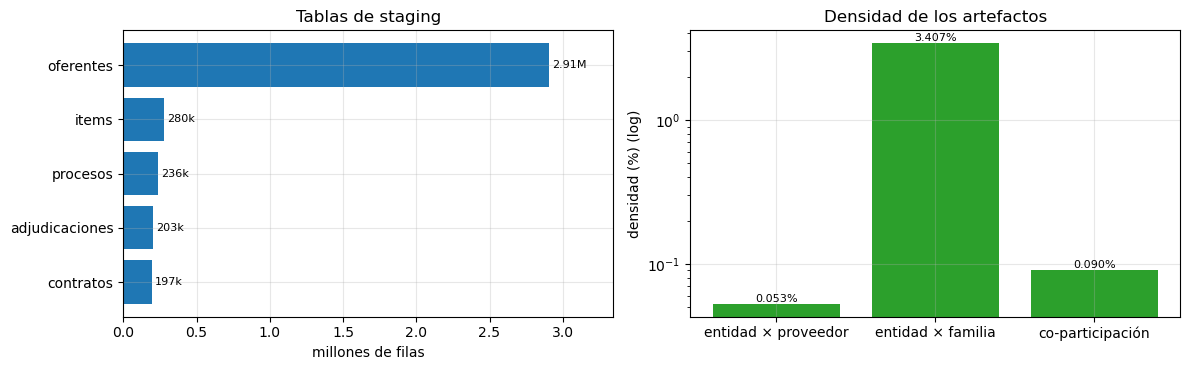

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
s_ = staging.sort_values("filas")
ax[0].barh(s_.tabla, s_.filas / 1e6, color="tab:blue")
ax[0].bar_label(ax[0].containers[0], labels=[f"{f / 1e6:.2f}M" if f >= 1e6 else f"{f / 1e3:,.0f}k" for f in s_.filas], fontsize=8, padding=2)
ax[0].set(xlim=(0, s_.filas.max() / 1e6 * 1.15), xlabel="millones de filas", title="Tablas de staging")
ax[1].bar(densidades.index, 100 * densidades.values, color="tab:green")
ax[1].bar_label(ax[1].containers[0], labels=[f"{100 * d:.3f}%" for d in densidades], fontsize=8)
ax[1].set(yscale="log", ylabel="densidad (%) (log)", title="Densidad de los artefactos")
mostrar_fig("datos")

- **236,229 procesos** en 36 meses (2023-2025): una fila por proceso

- **Oferentes** es la tabla más grande (2.9M filas): una fila por cada postor de cada proceso (13.5 por proceso)

- **Adjudicaciones, ítems y contratos** tienen 1.1-1.2 filas por proceso (lotes, varios ítems o varios contratos)

- **Matrices dispersas:** entidad × proveedor 0.053%; **84.9%** de los proveedores le vende a una sola entidad

- **Co-participación:** 60,213 proveedores y 1.64M aristas (0.09%); entidad × familia es la más densa (3.4%)

- **cola larga** (proveedores de una sola entidad o un solo proceso) condiciona todas las técnicas

---
### **3. Técnicas y parámetros**

In [5]:
T = lambda parte, tec, preg, art, param, donde: dict(parte=parte, tecnica=tec, pregunta=preg, artefacto=art, parametros=param, corre_en=donde)
tecnicas = pd.DataFrame([
    T("II", "KMeans++", "PQ1, PQ2", "features_*", "k = 4 (máximo de silueta común)", "Spark MLlib"),
    T("II", "DBSCAN / HDBSCAN", "PQ1", "features_*", "eps p95; min_cluster_size 10-100", "local"),
    T("II", "Ward (jerárquico)", "PQ2", "features_proveedor", "k = 4, muestra 5,000", "local (muestra)"),
    T("III", "Vecindario (user / item)", "PQ3", "matriz entidad × proveedor", "k = 100 vecinas", "local"),
    T("III", "Contenido (TF-IDF + LSA)", "PQ3", "texto de procesos", "HNSW para vecinos", "local"),
    T("III", "ALS implícito", "PQ1, PQ3", "matriz entidad × proveedor", "rank y alpha por NDCG en validación", "Spark MLlib"),
    T("III", "Híbrido ALS + contenido", "PQ3", "ambos", "w = 0.7", "local"),
    T("IV", "PageRank", "PQ1", "grafo_bipartito", "d = 0.85, peso n_adj, no dirigido", "Spark + scipy"),
    T("IV", "HITS", "PQ1", "grafo_bipartito", "peso n_adj (SVD de rango 1)", "scipy"),
    T("V", "Girvan–Newman", "PQ2", "grafo_coparticipacion", "muestra de 300 nodos", "local (muestra)"),
    T("V", "Espectral", "PQ2", "núcleo", "k = 28 (Q ≥ 99% del máximo)", "local (núcleo)"),
    T("V", "Louvain", "PQ2", "núcleo", "γ = 1.25 (Q y estabilidad)", "local (núcleo)"),
    T("V", "BigCLAM", "PQ2", "núcleo", "K = 100 (AUC), δ teórico", "local (núcleo)"),
    T("V", "Label Propagation", "PQ2", "grafo completo", "20 iteraciones, con inercia", "Spark"),
    T("VI", "Node2Vec", "PQ2, PQ3", "co-participación sin hubs", "dim 32, p, q en {0.25, 1, 4}", "local"),
    T("VI", "SVD", "PQ2", "co-participación sin hubs", "dim 32", "local"),
    T("VI", "Predicción de enlaces", "PQ3", "embeddings 2023", "random forest + Hadamard", "local")])
tecnicas

,parte,tecnica,pregunta,artefacto,parametros,corre_en
0,II,KMeans++,"PQ1, PQ2",features_*,k = 4 (máximo de silueta común),Spark MLlib
1,II,DBSCAN / HDBSCAN,PQ1,features_*,eps p95; min_cluster_size 10-100,local
2,II,Ward (jerárquico),PQ2,features_proveedor,"k = 4, muestra 5,000",local (muestra)
3,III,Vecindario (user / item),PQ3,matriz entidad × proveedor,k = 100 vecinas,local
4,III,Contenido (TF-IDF + LSA),PQ3,texto de procesos,HNSW para vecinos,local
5,III,ALS implícito,"PQ1, PQ3",matriz entidad × proveedor,rank y alpha por NDCG en validación,Spark MLlib
6,III,Híbrido ALS + contenido,PQ3,ambos,w = 0.7,local
7,IV,PageRank,PQ1,grafo_bipartito,"d = 0.85, peso n_adj, no dirigido",Spark + scipy
8,IV,HITS,PQ1,grafo_bipartito,peso n_adj (SVD de rango 1),scipy
9,V,Girvan–Newman,PQ2,grafo_coparticipacion,muestra de 300 nodos,local (muestra)


- **17 técnicas** en 5 partes; cada parámetro se eligió con un criterio explícito

- **Spark** donde se mueve el dataset completo (KMeans, ALS, PageRank, LPA)

- **Local** donde el dato cabe en memoria (grafos del núcleo, embeddings)

- **Muestra o núcleo** solo donde el costo lo exige (Ward, Girvan–Newman, métodos del núcleo de comunidades)

---
### **4. Desempeño**

Cada técnica contra su **línea base**: un modelo trivial o el azar; si no la supera, no aporta

In [6]:
pr = tabla("03_Recomend", "e_hibrido", "comparacion_test").set_index("modelo")
sus = tabla("03_Recomend", "f_analisis", "sustitutos_resumen").set_index("metodo").pct_coparticipan / 100
cfg5 = datos("05_Comunidad", "config.json")
gn = tabla("05_Comunidad", "b_particion", "gn_vs_louvain").set_index("metodo")
bc = tabla("05_Comunidad", "c_solapadas", "eleccion_k")
bc_k = bc.loc[bc.K == cfg5["k_bigclam"]].iloc[0]
lp = tabla("06_Representacion", "d_enlaces", "resultados")
lp_best, lp_aa = lp.iloc[0], lp.set_index("config").loc["adamic_adar"]
dim = tabla("06_Representacion", "b_node2vec", "dimension").iloc[0]
ari_km = tabla("02_Clustering", "e_analisis", "ari_metodos").set_index(["sujeto", "metodo"])
D = lambda parte, tec, met, val, ref, vref: dict(parte=parte, tecnica=tec, metrica=met, valor=val, referencia=ref, valor_ref=vref)
desempeno = pd.DataFrame([
    D("II", "KMeans++ vs Ward (proveedores)", "ARI entre métodos", ari_km.loc[("proveedor", "kmeans"), "jerarquico"], "azar", 0.0),
    D("III", "Híbrido", "NDCG@10 (2025)", pr.loc["híbrido", "ndcg@10"], "popularidad regional", pr.loc["popularidad regional", "ndcg@10"]),
    D("III", "Sustitutos ALS", "% que co-participan", sus["als"], "azar en la familia", sus["azar (misma familia)"]),
    D("V", "Louvain", "Q (binaria)", cfg5["q_real_binaria"], "nulo de configuración", cfg5["q_nulo"]),
    D("V", "Girvan–Newman", "NMI con la referencia", gn.loc["girvan-newman (muestra)", "nmi_vs_ref"], "azar", 0.0),
    D("V", "BigCLAM", "AUC aristas retenidas", bc_k.auc, "producto de grados", bc_k.auc_piso),
    D("VI", "Node2Vec (dim)", "AUC coseno 2023 → 2024", dim.auc_coseno, "azar", 0.5),
    D("VI", "Enlaces (random forest)", "PR-AUC test 2025", lp_best.pr_auc, "Adamic-Adar", lp_aa.pr_auc)])
desempeno.round(3)

,parte,tecnica,metrica,valor,referencia,valor_ref
0,II,KMeans++ vs Ward (proveedores),ARI entre métodos,0.540,azar,0.000
1,III,Híbrido,NDCG@10 (2025),0.099,popularidad regional,0.081
2,III,Sustitutos ALS,% que co-participan,0.337,azar en la familia,0.120
3,V,Louvain,Q (binaria),0.854,nulo de configuración,0.238
4,V,Girvan–Newman,NMI con la referencia,0.923,azar,0.000
5,V,BigCLAM,AUC aristas retenidas,0.971,producto de grados,0.870
6,VI,Node2Vec (dim),AUC coseno 2023 → 2024,0.879,azar,0.500
7,VI,Enlaces (random forest),PR-AUC test 2025,0.721,Adamic-Adar,0.637


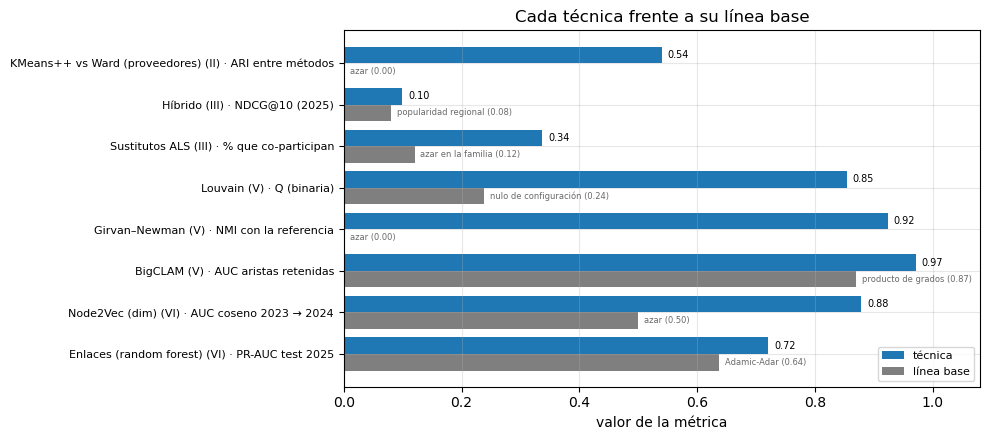

In [7]:
d_ = desempeno.iloc[::-1]
y_ = np.arange(len(d_))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(y_ + .2, d_.valor, .4, label="técnica")
ax.barh(y_ - .2, d_.valor_ref, .4, color="tab:gray", label="línea base")
ax.set_yticks(y_); ax.set_yticklabels([f"{t} ({p}) · {m}" for t, p, m in zip(d_.tecnica, d_.parte, d_.metrica)], fontsize=8)
for yy, v, r, vr in zip(y_, d_.valor, d_.referencia, d_.valor_ref):
    ax.text(v + .01, yy + .2, f"{v:.2f}", va="center", fontsize=7)
    ax.text(vr + .01, yy - .2, f"{r} ({vr:.2f})", va="center", fontsize=6, color="dimgray")
ax.set(xlim=(0, 1.08), xlabel="valor de la métrica", title="Cada técnica frente a su línea base"); ax.legend(fontsize=8, loc="lower right")
mostrar_fig("desempeno")

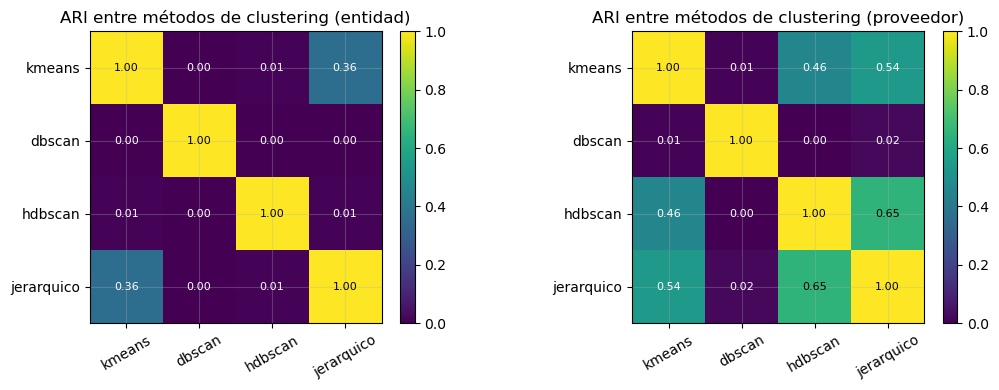

In [8]:
ari = tabla("02_Clustering", "e_analisis", "ari_metodos")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, s in zip(ax, ["entidad", "proveedor"]):
    M_ = ari[ari.sujeto == s].set_index("metodo")[["kmeans", "dbscan", "hdbscan", "jerarquico"]]
    im = a_.imshow(M_.to_numpy(), vmin=0, vmax=1, cmap="viridis")
    a_.set_xticks(range(4)); a_.set_xticklabels(M_.columns, rotation=30); a_.set_yticks(range(4)); a_.set_yticklabels(M_.index)
    for (r, c), v in np.ndenumerate(M_.to_numpy()):
        a_.text(c, r, f"{v:.2f}", ha="center", va="center", color="w" if v < .6 else "k", fontsize=8)
    a_.set_title(f"ARI entre métodos de clustering ({s})")
    plt.colorbar(im, ax=a_, fraction=.046, pad=.04)
mostrar_fig("clustering_ari")

- **Todas las técnicas superan su línea base:** ningún resultado es atribuible al azar o a un modelo trivial

- **Mayor ventaja:** Louvain (Q 0.85 vs 0.24 del nulo) y los sustitutos de ALS (34% vs 12% al azar, ×2.8)

- **Ventajas chicas en valor absoluto:** híbrido (NDCG 0.10 vs 0.08), BigCLAM (AUC 0.97 vs 0.87) 

- Enlaces (PR-AUC 0.72 vs 0.64): la cola larga y el grado ya explican mucho

- **Clustering:** KMeans y Ward coinciden (ARI 0.54 en proveedores, 0.36 en entidades)

- DBSCAN no coincide con ningún método (ARI ≈ 0): deja casi todo en un grupo

---
### **5. Escritura de resultados**

In [9]:
escritos = guardar_tablas({"tecnicas": tecnicas, "desempeno": desempeno})

Escrito en 07_Analisis/temp/a_recuento/: tecnicas, desempeno


#### a. Verificación

In [10]:
verificar_salidas(escritos)

OK: 2 tablas (parquet + json) | 3 figuras: clustering_ari, datos, desempeno


---
### **6. Cerrar sesión**

In [11]:
spark.stop()